
# Notebook 3 — Descriptive Analysis (Synthetic Sound the Alarm)

This notebook reproduces the descriptive analytics from the real-data version, using the **synthetic cleaned dataset**.

**Outputs saved to:**
- Figures → `reports/figures/eda/`
- Tables  → `reports/artifacts/eda/`

> Tip: Run all cells from top to bottom on a fresh clone to regenerate consistent outputs.


In [1]:
from pathlib import Path
import pandas as pd

# Repo root is the folder that contains BOTH 'notebook/' and 'data/'
ROOT = Path.cwd().parent  # <- since already inside .../notebook

RAW = ROOT / "data" / "raw" / "synthetic_sound_the_alarm_2015_2025_dirty.csv"
INTERIM = ROOT / "data" / "interim" / "synthetic_sound_the_alarm_2015_2025_clean.csv"
DATA_PATH = INTERIM  # or RAW

FIG_DIR = ROOT / "reports" / "figures" / "eda"
TAB_DIR = ROOT / "reports" / "artifacts" / "eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

print("Notebook CWD:", Path.cwd())
print("Repo ROOT:", ROOT)
print("Looking for:", DATA_PATH)
print("Exists?", DATA_PATH.exists())



Notebook CWD: C:\Users\syksh\Documents\community_safety_forecasting\notebook
Repo ROOT: C:\Users\syksh\Documents\community_safety_forecasting
Looking for: C:\Users\syksh\Documents\community_safety_forecasting\data\interim\synthetic_sound_the_alarm_2015_2025_clean.csv
Exists? True


## 1) Load Data

In [2]:
# Parse the CSV; parse a date column if present (date/Date/DATE)
assert DATA_PATH.exists(), f"File not found: {DATA_PATH.resolve()}"

cols0 = pd.read_csv(DATA_PATH, nrows=0).columns
date_cols = [c for c in ("date", "Date", "DATE") if c in cols0] or None

df = pd.read_csv(DATA_PATH, parse_dates=date_cols)
print("Loaded:", DATA_PATH)
print("Shape:", df.shape)
df.head()



Loaded: C:\Users\syksh\Documents\community_safety_forecasting\data\interim\synthetic_sound_the_alarm_2015_2025_clean.csv
Shape: (25764, 11)


,date,zip,territory,people_served_num,smoke_alarms_installed_num,fire_escape_plans_num,additional_hazards_num,year,month,dow,is_weekend
0,2017-04-08,93450,Central Coast,2,1,2,0,2017,4,5,1
1,2015-08-29,92066,San Diego,7,7,1,0,2015,8,5,1
2,2016-03-02,92780,Orange County,8,3,1,0,2016,3,2,0
3,2023-05-17,90127,LA Metro,8,6,1,1,2023,5,2,0
4,2017-04-23,92316,Inland Empire,8,4,0,0,2017,4,6,1


## 2) Sanity Checks & Basic Info

In [3]:

# Dtypes and basic NA summary
print(df.dtypes)
na_summary = df.isna().sum().sort_values(ascending=False)
display(na_summary)

# Ensure required columns exist
required = ["date", "territory", "smoke_alarms_installed_num", "people_served_num"]
missing = [c for c in required if c not in df.columns]
assert not missing, f"Missing required columns: {missing}"


date                          datetime64[ns]
zip                                    int64
territory                             object
people_served_num                      int64
smoke_alarms_installed_num             int64
fire_escape_plans_num                  int64
additional_hazards_num                 int64
year                                   int64
month                                  int64
dow                                    int64
is_weekend                             int64
dtype: object


date                          0
zip                           0
territory                     0
people_served_num             0
smoke_alarms_installed_num    0
fire_escape_plans_num         0
additional_hazards_num        0
year                          0
month                         0
dow                           0
is_weekend                    0
dtype: int64

## 3) Overview KPIs

In [4]:

total_installs = int(df["smoke_alarms_installed_num"].sum())
total_people = int(df["people_served_num"].sum())
total_days = df["date"].nunique()
min_date, max_date = df["date"].min(), df["date"].max()

kpis = pd.DataFrame({
    "metric": ["Total Installs", "Total People Served", "Active Days", "Start Date", "End Date"],
    "value": [total_installs, total_people, total_days, min_date, max_date]
})
display(kpis)

# Save KPIs
kpis.to_csv(TAB_DIR / "kpis.csv", index=False)


,metric,value
0,Total Installs,94956
1,Total People Served,111341
2,Active Days,3884
3,Start Date,2015-01-01 00:00:00
4,End Date,2025-09-20 00:00:00


## 4) Trends Over Time (Yearly / Monthly)

In [5]:

df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["ym"] = df["date"].dt.to_period("M").dt.to_timestamp()

yearly = df.groupby("year", as_index=False)[["smoke_alarms_installed_num","people_served_num"]].sum()
monthly = df.groupby("ym", as_index=False)[["smoke_alarms_installed_num","people_served_num"]].sum()

display(yearly.head())
display(monthly.head())

# Save tables
yearly.to_csv(TAB_DIR / "yearly_totals.csv", index=False)
monthly.to_csv(TAB_DIR / "monthly_totals.csv", index=False)


,year,smoke_alarms_installed_num,people_served_num
0,2015,8383,9691
1,2016,8605,10128
2,2017,8891,10614
3,2018,9256,10819
4,2019,9565,11074


,ym,smoke_alarms_installed_num,people_served_num
0,2015-01-01,482,536
1,2015-02-01,595,613
2,2015-03-01,716,854
3,2015-04-01,1004,1176
4,2015-05-01,996,1188


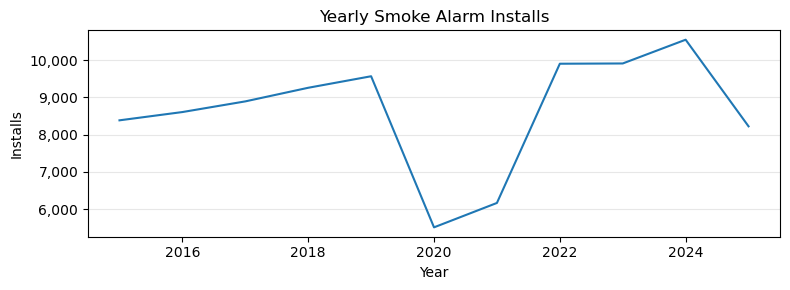

In [6]:
# Yearly installs (robust plot cell)
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Safety: make sure needed columns exist
assert {"year", "smoke_alarms_installed_num"} <= set(yearly.columns), "yearly table missing columns"

ys = yearly.sort_values("year").copy()
ys["year"] = ys["year"].astype(int)

fig, ax = plt.subplots(figsize=(8,3))
ax.plot(ys["year"], ys["smoke_alarms_installed_num"])
ax.set(title="Yearly Smoke Alarm Installs", xlabel="Year", ylabel="Installs")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(True, axis="y", alpha=0.3)
fig.tight_layout()

# Optional save (uncomment when you want to write the file)
FIG_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIG_DIR / "yearly_installs.png", dpi=150)

plt.show()



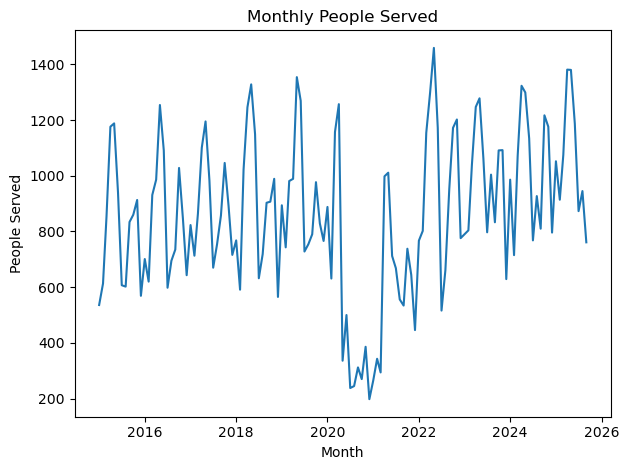

In [22]:
# Plot: Monthly people served (one figure)
import matplotlib.pyplot as plt

assert 'monthly' in globals(), "Run the cell that creates `monthly` first."

m = monthly.sort_values('ym')
plt.figure()
plt.plot(m['ym'], m['people_served_num'])
plt.title("Monthly People Served")
plt.xlabel("Month")
plt.ylabel("People Served")
plt.tight_layout()
plt.savefig(FIG_DIR / "monthly_people_served.png", dpi=150)
plt.show()


## 5) Territory Comparisons

In [8]:

territory_totals = (
    df.groupby("territory", as_index=False)[["smoke_alarms_installed_num","people_served_num"]]
      .sum()
      .sort_values("smoke_alarms_installed_num", ascending=False)
)
display(territory_totals.head(15))

territory_totals.to_csv(TAB_DIR / "territory_totals.csv", index=False)


,territory,smoke_alarms_installed_num,people_served_num
2,LA Metro,40036,45391
1,Inland Empire,19980,23389
3,Orange County,15925,18962
4,San Diego,12977,15729
0,Central Coast,6038,7870


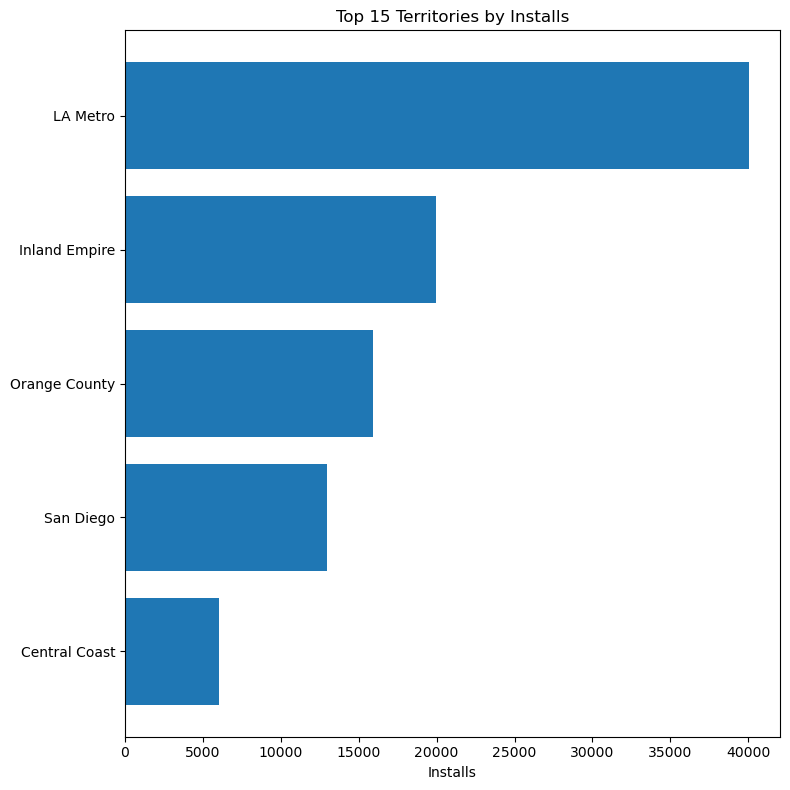

In [9]:

# Plot: Top 15 territories by installs (single figure)
topn = 15
tt = territory_totals.head(topn).copy()
plt.figure(figsize=(8, 0.4*topn + 2))
plt.barh(tt["territory"][::-1], tt["smoke_alarms_installed_num"][::-1])
plt.title(f"Top {topn} Territories by Installs")
plt.xlabel("Installs")
plt.tight_layout()
plt.savefig(FIG_DIR / "territory_top15_installs.png", dpi=150)
plt.show()


## 6) Day-of-Week & Weekend Effects

In [10]:

df["dow"] = df["date"].dt.dayofweek  # 0=Mon ... 6=Sun
dow_stats = df.groupby("dow", as_index=False)[["smoke_alarms_installed_num","people_served_num"]].mean()
display(dow_stats)

dow_stats.to_csv(TAB_DIR / "dow_means.csv", index=False)


,dow,smoke_alarms_installed_num,people_served_num
0,0,3.664976,4.186754
1,1,3.603219,4.128212
2,2,3.596360,4.134904
3,3,3.636103,4.069810
4,4,3.611920,4.209832
5,5,3.511046,4.069201
6,6,4.054839,5.192047


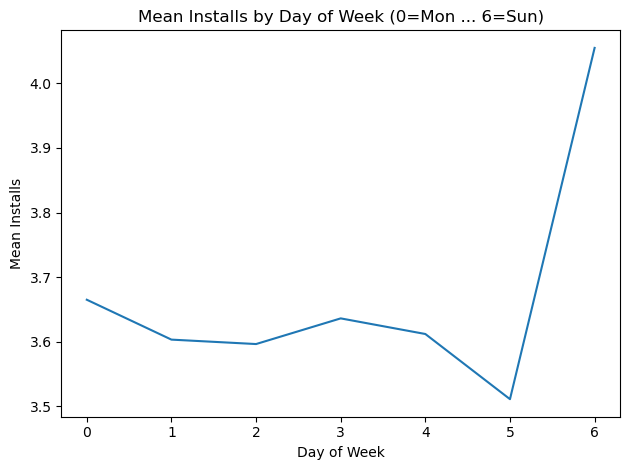

In [11]:

# Plot: Mean installs by day of week
plt.figure()
plt.plot(dow_stats["dow"], dow_stats["smoke_alarms_installed_num"])
plt.title("Mean Installs by Day of Week (0=Mon ... 6=Sun)")
plt.xlabel("Day of Week")
plt.ylabel("Mean Installs")
plt.tight_layout()
plt.savefig(FIG_DIR / "dow_mean_installs.png", dpi=150)
plt.show()


In [12]:

# Weekend vs weekday comparison
df["is_weekend"] = df["date"].dt.dayofweek.isin([5, 6]).astype(int)
weekend_stats = df.groupby("is_weekend", as_index=False)[["smoke_alarms_installed_num","people_served_num"]].mean()
display(weekend_stats)

weekend_stats.to_csv(TAB_DIR / "weekend_means.csv", index=False)


,is_weekend,smoke_alarms_installed_num,people_served_num
0,0,3.621956,4.144459
1,1,3.836185,4.740562


## 7) Cross-Metric Relationships

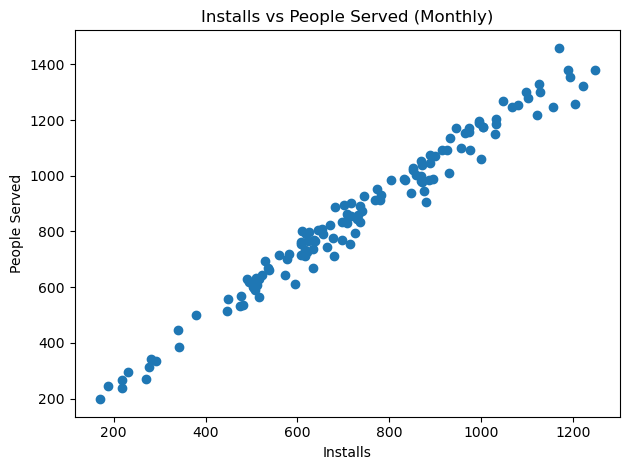

In [13]:

# Scatter: installs vs people served (aggregated monthly to reduce noise)
agg = df.groupby("ym", as_index=False)[["smoke_alarms_installed_num","people_served_num"]].sum()
plt.figure()
plt.scatter(agg["smoke_alarms_installed_num"], agg["people_served_num"])
plt.title("Installs vs People Served (Monthly)")
plt.xlabel("Installs")
plt.ylabel("People Served")
plt.tight_layout()
plt.savefig(FIG_DIR / "scatter_installs_vs_people_monthly.png", dpi=150)
plt.show()


In [14]:
# columns that reflect activity/outputs (not IDs or time flags)
behavior_cols = [
    "smoke_alarms_installed_num",
    "people_served_num",
    "fire_escape_plans_num",
    "additional_hazards_num",
]
corr = df[behavior_cols].corr(method="pearson")   # or method="spearman"
display(corr)

corr.to_csv(TAB_DIR / "numeric_correlation_behavior_only.csv")  # keep index

,smoke_alarms_installed_num,people_served_num,fire_escape_plans_num,additional_hazards_num
smoke_alarms_installed_num,1.000000,0.732005,-0.018217,-0.020122
people_served_num,0.732005,1.000000,-0.023124,-0.014492
fire_escape_plans_num,-0.018217,-0.023124,1.000000,-0.023853
additional_hazards_num,-0.020122,-0.014492,-0.023853,1.000000


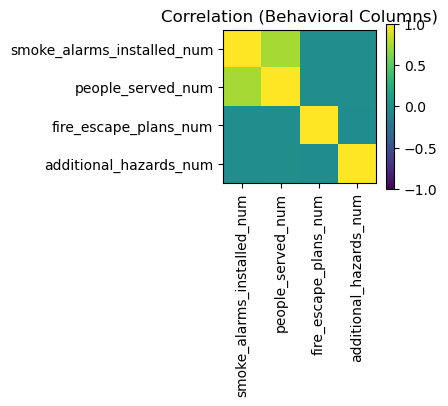

In [15]:
import matplotlib.pyplot as plt
plt.figure(figsize=(4.5,4))
plt.imshow(corr, vmin=-1, vmax=1, aspect="equal")
plt.title("Correlation (Behavioral Columns)")
plt.xticks(range(len(behavior_cols)), behavior_cols, rotation=90)
plt.yticks(range(len(behavior_cols)), behavior_cols)
plt.colorbar()
plt.tight_layout()
plt.savefig(FIG_DIR / "corr_behavior_heatmap.png", dpi=150)
plt.show()


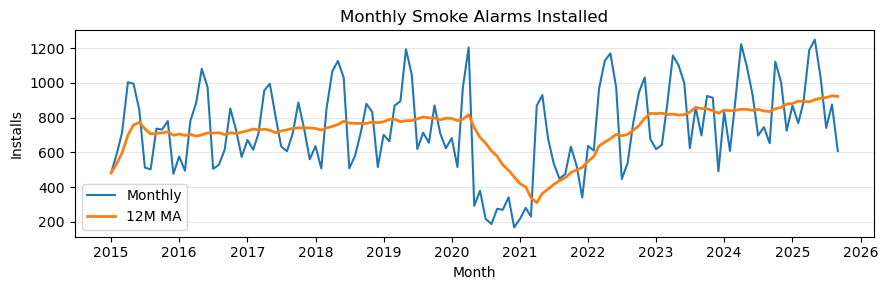

In [16]:
# Monthly installs with a 12-month moving average (trend)
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Rebuild monthly if needed
if 'monthly' not in globals():
    df['ym'] = df['date'].dt.to_period('M').dt.to_timestamp()
    monthly = df.groupby('ym', as_index=False)[['smoke_alarms_installed_num','people_served_num']].sum()

m = monthly.sort_values('ym').copy()
ma = m['smoke_alarms_installed_num'].rolling(12, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(9,3))
ax.plot(m['ym'], m['smoke_alarms_installed_num'], label='Monthly')
ax.plot(m['ym'], ma, linewidth=2, label='12M MA')
ax.set_title("Monthly Smoke Alarms Installed")
ax.set_xlabel("Month"); ax.set_ylabel("Installs")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(mdates.YearLocator()))
ax.grid(True, axis='y', alpha=0.3); ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "monthly_installs.png", dpi=150)
plt.show()


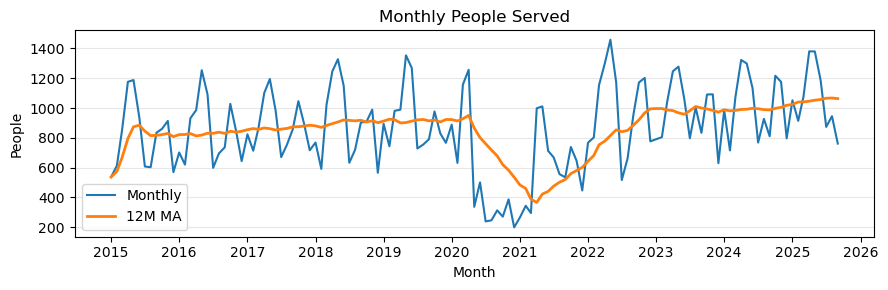

In [17]:
# Monthly people served with 12-month moving average

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

m = monthly.sort_values('ym').copy()
ma = m['people_served_num'].rolling(12, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(9,3))
ax.plot(m['ym'], m['people_served_num'], label='Monthly')
ax.plot(m['ym'], ma, linewidth=2, label='12M MA')
ax.set_title("Monthly People Served")
ax.set_xlabel("Month"); ax.set_ylabel("People")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(mdates.YearLocator()))
ax.grid(True, axis='y', alpha=0.3); ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "monthly_people_served.png", dpi=150)
plt.show()


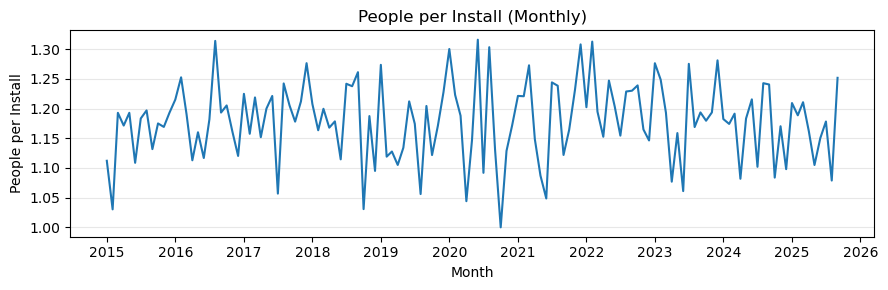

In [18]:
#Efficiency over time: people per install (stability / drift)

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

m = monthly.sort_values('ym').copy()
m['people_per_install'] = m['people_served_num'] / m['smoke_alarms_installed_num']

fig, ax = plt.subplots(figsize=(9,3))
ax.plot(m['ym'], m['people_per_install'])
ax.set_title("People per Install (Monthly)")
ax.set_xlabel("Month"); ax.set_ylabel("People per Install")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(mdates.YearLocator()))
ax.grid(True, axis='y', alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "people_per_install_monthly.png", dpi=150)
plt.show()


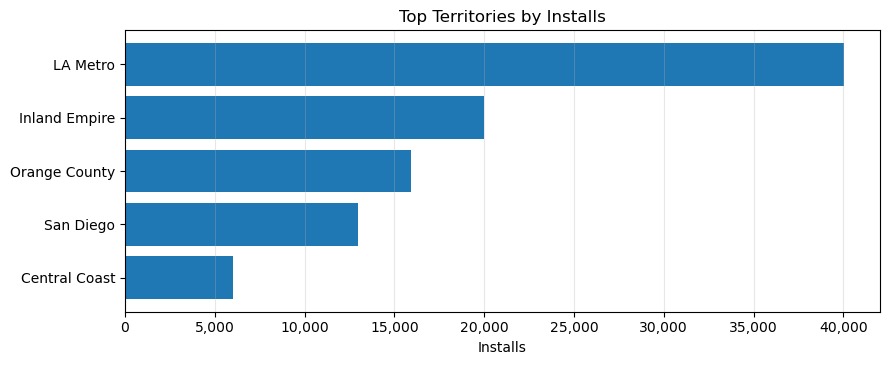

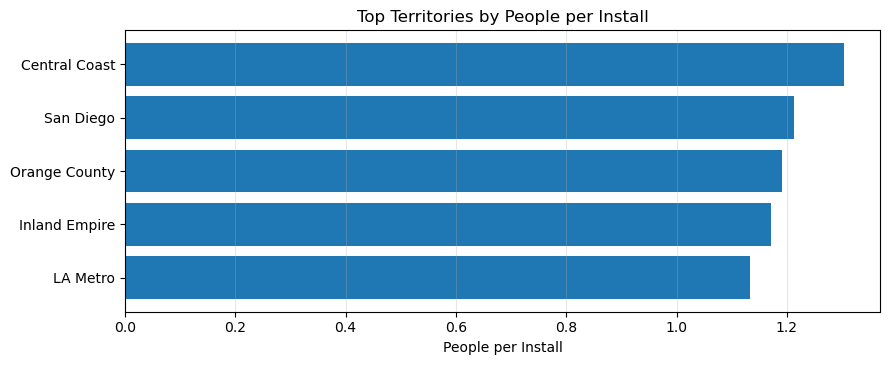

In [19]:
# Top territories by installs (volume) and by efficiency

import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Totals by territory
territory_totals = (
    df.groupby("territory", as_index=False)[["smoke_alarms_installed_num","people_served_num"]]
      .sum()
      .sort_values("smoke_alarms_installed_num", ascending=False)
)

# A) Top 10 by installs (volume)
top = territory_totals.head(10).copy()
fig, ax = plt.subplots(figsize=(9, 0.45*len(top)+1.5))
ax.barh(top["territory"][::-1], top["smoke_alarms_installed_num"][::-1])
ax.set_title("Top Territories by Installs")
ax.set_xlabel("Installs"); ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(True, axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "territory_top_installs.png", dpi=150)
plt.show()

# B) Top 10 by people-per-install (efficiency)
tm = territory_totals.copy()
tm["people_per_install"] = tm["people_served_num"] / tm["smoke_alarms_installed_num"]
top_eff = tm.sort_values("people_per_install", ascending=False).head(10)
fig, ax = plt.subplots(figsize=(9, 0.45*len(top_eff)+1.5))
ax.barh(top_eff["territory"][::-1], top_eff["people_per_install"][::-1])
ax.set_title("Top Territories by People per Install")
ax.set_xlabel("People per Install")
ax.grid(True, axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "territory_top_efficiency.png", dpi=150)
plt.show()


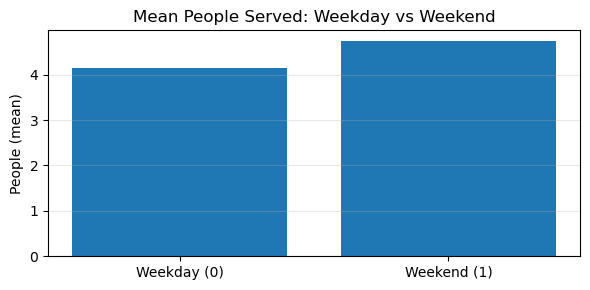

In [20]:
# Weekday vs weekend performance (scheduling signal)

import matplotlib.pyplot as plt

df["is_weekend"] = df["date"].dt.dayofweek.isin([5,6]).astype(int)
weekend_stats = df.groupby("is_weekend", as_index=False)[["people_served_num","smoke_alarms_installed_num"]].mean()

labels = ["Weekday (0)", "Weekend (1)"]
vals = weekend_stats.sort_values("is_weekend")["people_served_num"].values

fig, ax = plt.subplots(figsize=(6,3))
ax.bar(labels, vals)
ax.set_title("Mean People Served: Weekday vs Weekend")
ax.set_ylabel("People (mean)")
ax.grid(True, axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "weekday_vs_weekend_people.png", dpi=150)
plt.show()


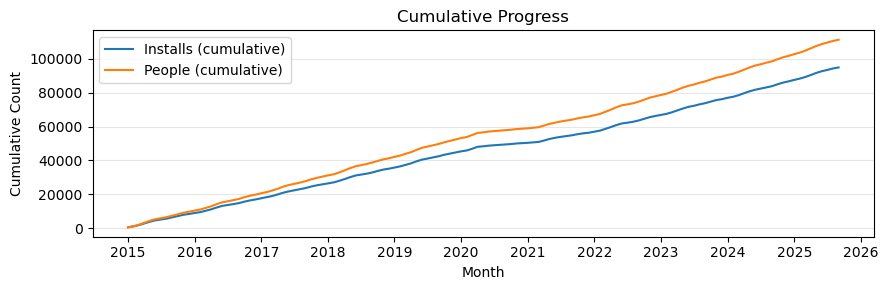

In [21]:
# (Optional) Cumulative installs & people (progress over time)

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

m = monthly.sort_values("ym").copy()
m["cum_installs"] = m["smoke_alarms_installed_num"].cumsum()
m["cum_people"]   = m["people_served_num"].cumsum()

fig, ax = plt.subplots(figsize=(9,3))
ax.plot(m["ym"], m["cum_installs"], label="Installs (cumulative)")
ax.plot(m["ym"], m["cum_people"],   label="People (cumulative)")
ax.set_title("Cumulative Progress")
ax.set_xlabel("Month"); ax.set_ylabel("Cumulative Count")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(mdates.YearLocator()))
ax.grid(True, axis="y", alpha=0.3); ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "cumulative_progress.png", dpi=150)
plt.show()
